# HCN: active-space Hamiltonian and variational π correlation

**Question:** how accurately can a symmetry-preserving variational circuit solve a justified nitrile π model, and how large is the remaining active-space truncation?

Use explicit molecular integrals and mapped-Hamiltonian checks, matched CASCI references, multiple optimization seeds, and a short C–N scan. All energies are nonrelativistic Born–Oppenheimer totals including nuclear repulsion. Run instructions and profiles: [README_HCN.md](README_HCN.md).


In [1]:
import os, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from pyscf import gto, scf, mcscf, ao2mo
from hcn_benchmark import (geometry_angstrom, build_problem, run_study,
                           validate_run, full_fci_reference, pbe_grid_control, provenance, require)

profile = os.environ.get("HCN_PROFILE", "default")
require(profile in {"smoke", "default"}, "Unknown HCN_PROFILE")
distances = [1.167] if profile == "smoke" else [1.067, 1.167, 1.267]
seeds = [0] if profile == "smoke" else [0, 1, 2]
maxiter = 30 if profile == "smoke" else 300
metadata = provenance()
print(json.dumps(metadata, indent=2))


{
  "python": "3.11.15",
  "packages": {
    "numpy": "1.26.4",
    "scipy": "1.17.1",
    "pennylane": "0.36.0",
    "autoray": "0.6.11",
    "autograd": "1.9.1",
    "pennylane-lightning": "0.37.0",
    "pyscf": "2.11.0",
    "h5py": "3.16.0",
    "matplotlib": "3.11.2",
    "nbclient": "0.11.0",
    "nbformat": "5.11.1",
    "ipykernel": "7.4.0"
  },
  "benchmark_source_sha256": "54ef180a831f6b32e1ddeefef0b78e40679ed2f6846fab15638cc734bb44d592",
  "geometry_unit": "angstrom",
  "charge": 0,
  "multiplicity": 1,
  "point_group": "C2v",
  "basis": "sto-3g",
  "active_space": "4 electrons in 4 spatial orbitals",
  "orbital_order": "canonical RHF, core0..4, active5..8, alpha/beta interleaved",
  "energy_convention": "total Born-Oppenheimer energy including nuclear repulsion",
  "reference_scope": "same PySCF integrals; independent CASCI and qubit-sector solvers",
  "classical_baseline_scope": "RHF and RKS-PBE use the full 11-orbital basis",
  "dft": "restricted PBE, grid level5",
  "scf

## 1. Geometry, orbitals, and active-space choice

Place H at $z=0$, C at $z=1.065$, and N at $z=2.232$ Å; charge 0, singlet, STO-3G. RHF gives 14 electrons and 11 spatial orbitals. Freeze occupied orbitals 0–4 and retain orbitals 5–8: two occupied π and two virtual π* orbitals, verified by C₂ᵥ B₁/B₂ symmetry labels and occupations. Exclude virtual orbitals 9–10. This CAS(4,4) requires eight qubits; the σ framework remains frozen. Canonical RHF orbitals are recomputed at each geometry and held fixed for CASCI/VQE; no CASSCF orbital optimization is performed.

The pinned differentiable-HF backend failed the reference-energy check for this geometry. Converged PySCF orbitals define the model; the rejected-backend evidence is recorded in [VALIDATION.md#hcn](VALIDATION.md#hcn).


In [2]:
coordinates = geometry_angstrom()
molecule = gto.M(atom=list(zip(["H", "C", "N"], coordinates)), unit="Angstrom",
                 basis="sto-3g", charge=0, spin=0, symmetry="C2v", verbose=0)
rhf = scf.RHF(molecule)
rhf.conv_tol = 1e-11
rhf.kernel()
require(rhf.converged, "RHF did not converge")
casci = mcscf.CASCI(rhf, 4, (2, 2))
casci.fcisolver.conv_tol = 1e-12
casci.kernel()
require(casci.converged, "CASCI did not converge")
problem = build_problem()
print("Geometry / Å:\n", coordinates)
print("Total electrons / spatial orbitals:", molecule.nelectron, molecule.nao)
print("Frozen / active / excluded virtual indices:", problem.reference["core_indices"],
      problem.reference["active_indices"], problem.reference["excluded_virtual_indices"])
print("MO index | symmetry | occupation | energy / Ha")
for i, (label, occupation, energy) in enumerate(zip(problem.reference["mo_symmetry_labels"],
        problem.reference["mo_occupations"], problem.reference["mo_energies_hartree"])):
    print(f"{i:2d} | {label:2s} | {occupation:.0f} | {energy: .8f}")


pyscf/lib/misc.py:148: UserWarning: OpenMP is not available. Setting omp_threads to 1 has no effects.
  warnings.warn('OpenMP is not available. '


Geometry / Å:
 [[0.    0.    0.   ]
 [0.    0.    1.065]
 [0.    0.    2.232]]
Total electrons / spatial orbitals: 14 11
Frozen / active / excluded virtual indices: [0, 1, 2, 3, 4] [5, 6, 7, 8] [9, 10]
MO index | symmetry | occupation | energy / Ha
 0 | A1 | 2 | -15.38330518
 1 | A1 | 2 | -11.07774412
 2 | A1 | 2 | -1.17342530
 3 | A1 | 2 | -0.75086687
 4 | A1 | 2 | -0.49243721
 5 | B1 | 2 | -0.43507287
 6 | B2 | 2 | -0.43507287
 7 | B1 | 0 |  0.34289042
 8 | B2 | 0 |  0.34289042
 9 | A1 | 0 |  0.54536700
10 | A1 | 0 |  1.28727317


## 2. Effective integrals, fermions, and qubits

CASCI returns spatial tensors and a scalar $E_{\mathrm{core}}$ containing nuclear repulsion and frozen-occupied energy. The effective one-electron tensor also contains frozen-occupied interactions. With spatial indices $p,q,r,s$ and spin labels $\sigma,\tau$,

$$H_{\mathrm{eff}}=E_{\mathrm{core}}I+\sum_{pq\sigma}h^{\mathrm{eff}}_{pq}a^\dagger_{p\sigma}a_{q\sigma}+\frac12\sum_{pqrs\sigma\tau}g_{pqrs}a^\dagger_{p\sigma}a^\dagger_{q\tau}a_{r\tau}a_{s\sigma}.$$

For these real spatial orbitals, convert PySCF chemist ERIs to $g_{pqrs}=(ps|rq)$ using `swapaxes(1,3)`. PennyLane expands the spin sums: four spatial orbitals become eight spin orbitals. Add $E_{\mathrm{core}}$ once. Jordan–Wigner uses $a_j^\dagger=(\prod_{k<j}Z_k)(X_j-iY_j)/2$, with spin-orbital wire order `[0,…,7]` α/β interleaved and wire 0 the leftmost bit. Electronic terms also contribute to the mapped identity coefficient.


In [3]:
one_body, core_energy = casci.get_h1eff()
two_body_chemist = ao2mo.restore(1, casci.get_h2eff(), 4)
two_body_pennylane = two_body_chemist.swapaxes(1, 3)
fermionic_hamiltonian = qml.qchem.fermionic_observable(
    np.array([core_energy]), one_body, two_body_pennylane)
qubit_hamiltonian = qml.jordan_wigner(fermionic_hamiltonian)
H_matrix = np.asarray(qml.matrix(qubit_hamiltonian, wire_order=range(8)))
np.testing.assert_allclose(H_matrix, problem.matrix, atol=1e-10, rtol=0)
np.testing.assert_allclose(H_matrix, H_matrix.conj().T, atol=1e-10, rtol=0)
print("Effective one-electron integrals / Ha:\n", one_body)
print("Two-electron tensor shape:", two_body_pennylane.shape)
print("Nuclear repulsion / frozen-core total constant / Ha:", molecule.energy_nuc(), core_energy)
print("Qubits / fermionic terms / Pauli terms:", 8, len(fermionic_hamiltonian),
      len(qubit_hamiltonian.terms()[0]))
print("Mapped-sector / CASCI totals / Ha:", problem.reference["sector_exact_hartree"], casci.e_tot)


Effective one-electron integrals / Ha:
 [[-1.98664176  0.          0.07689488  0.        ]
 [ 0.         -1.98664176  0.          0.07689488]
 [ 0.07689488  0.         -1.58471392  0.        ]
 [ 0.          0.07689488  0.         -1.58471392]]
Two-electron tensor shape: (4, 4, 4, 4)
Nuclear repulsion / frozen-core total constant / Ha: 23.685824191957728 -86.83116333561954
Qubits / fermionic terms / Pauli terms: 8 529 185
Mapped-sector / CASCI totals / Ha: -91.77508487838232 -91.77508487838224


## 3. HF preparation and symmetry-preserving circuit

Prepare $|11110000\rangle$ and apply six GateFabric layers with `include_pi=True`. GateFabric combines local double-excitation and spin-adapted orbital-rotation blocks. This circuit preserves electron number and total spin; both are evaluated numerically. The fixed π rotations rearrange occupations: zero or small trainable weights are not assumed to produce a near-HF state. Optimize its exact dense-observable expectation with L-BFGS-B and adjoint gradients. This is an eight-qubit statevector simulation, not a measurement-cost benchmark. CASCI or exact eigenvalues are used only for validation, not optimization.


In [4]:
hf_bits = qml.qchem.hf_state(4, 8)
device = qml.device("default.qubit", wires=8)

@qml.qnode(device)
def hf_energy():
    qml.BasisState(hf_bits, wires=range(8))
    return qml.expval(qml.Hermitian(H_matrix, wires=range(8)))

@qml.qnode(device, interface="autograd", diff_method="adjoint")
def energy_circuit(weights):
    qml.GateFabric(weights, wires=range(8), init_state=hf_bits, include_pi=True)
    return qml.expval(qml.Hermitian(H_matrix, wires=range(8)))

np.testing.assert_allclose(float(hf_energy()), rhf.e_tot, atol=1e-8, rtol=0)
initial_weights = np.random.default_rng(0).normal(scale=.1, size=qml.GateFabric.shape(6, 8))
print("HF occupations:", hf_bits)
print("Variational parameters:", initial_weights.size)
print(qml.draw(energy_circuit)(initial_weights))
print("Initial circuit energy / Ha:", float(energy_circuit(initial_weights)))


HF occupations: [1 1 1 1 0 0 0 0]
Variational parameters: 36
0: ─╭GateFabric(M0)─┤ ╭<𝓗(M1)>
1: ─├GateFabric(M0)─┤ ├<𝓗(M1)>
2: ─├GateFabric(M0)─┤ ├<𝓗(M1)>
3: ─├GateFabric(M0)─┤ ├<𝓗(M1)>
4: ─├GateFabric(M0)─┤ ├<𝓗(M1)>
5: ─├GateFabric(M0)─┤ ├<𝓗(M1)>
6: ─├GateFabric(M0)─┤ ├<𝓗(M1)>
7: ─╰GateFabric(M0)─┤ ╰<𝓗(M1)>

M0 = 
[[[ 0.01257302 -0.01321049]
  [ 0.06404227  0.01049001]
  [-0.05356694  0.03615951]]

 [[ 0.1304      0.0947081 ]
  [-0.07037352 -0.12654215]
  [-0.06232745  0.0041326 ]]

 [[-0.23250308 -0.02187917]
  [-0.12459109 -0.07322674]
  [-0.0544259  -0.03163002]]

 [[ 0.04116305  0.10425134]
  [-0.01285347  0.13664635]
  [-0.06651947  0.03515101]]

 [[ 0.09034702  0.00940123]
  [-0.07434992 -0.09217254]
  [-0.04577258  0.02201951]]

 [[-0.10096182 -0.02091756]
  [-0.0159225   0.05408456]
  [ 0.02146591  0.03553727]]]
M1 = 
[[-86.83116334+0.j   0.        +0.j   0.        +0.j ...   0.        +0.j
    0.        +0.j   0.        +0.j]
 [  0.        +0.j -88.41587725+0.j   0.        +0.

## 4. Optimization and fixed-H–C potential-energy scan

Repeat construction at each C–N length and use all seeds independently. Save initial, final, and best evaluated energies, the matching best parameters, full evaluation traces, and optimizer status. Line-search evaluations are not accepted iterations. A short smoke run may exhaust its budget; its status remains explicit and cannot certify convergence.

RHF/PBE use the full 11-orbital basis; CASCI and VQE use CAS(4,4). Their differences combine method and truncation effects. The small scan tests local behavior, not full C≡N dissociation or binding affinity.


In [5]:
rows = run_study(distances=distances, seeds=seeds, layers=6, maxiter=maxiter)
print("C–N / Å | seed | best / Ha | gap / Ha | converged | variance / Ha²")
for row in rows:
    for run in row["runs"]:
        print(f"{row['reference']['r_cn_angstrom']:.3f} | {run['seed']} | "
              f"{run['best_energy_hartree']: .10f} | {run['gap_hartree']:.2e} | "
              f"{run['optimizer_success']} | {run['energy_variance_hartree2']:.2e}")


C–N / Å | seed | best / Ha | gap / Ha | converged | variance / Ha²
1.067 | 0 | -91.7297942276 | 1.36e-10 | True | 1.56e-10
1.067 | 1 | -91.7297942276 | 1.09e-10 | True | 1.50e-10
1.067 | 2 | -91.7297942275 | 1.58e-10 | True | 1.88e-10
1.167 | 0 | -91.7750848780 | 3.34e-10 | True | 2.82e-10
1.167 | 1 | -91.7750848783 | 5.98e-11 | True | 8.33e-11
1.167 | 2 | -91.7750848781 | 3.02e-10 | True | 2.57e-10
1.267 | 0 | -91.7649168610 | 8.05e-11 | True | 4.42e-11
1.267 | 1 | -91.7649168609 | 1.74e-10 | True | 1.17e-10
1.267 | 2 | -91.7649168609 | 1.43e-10 | True | 1.15e-10


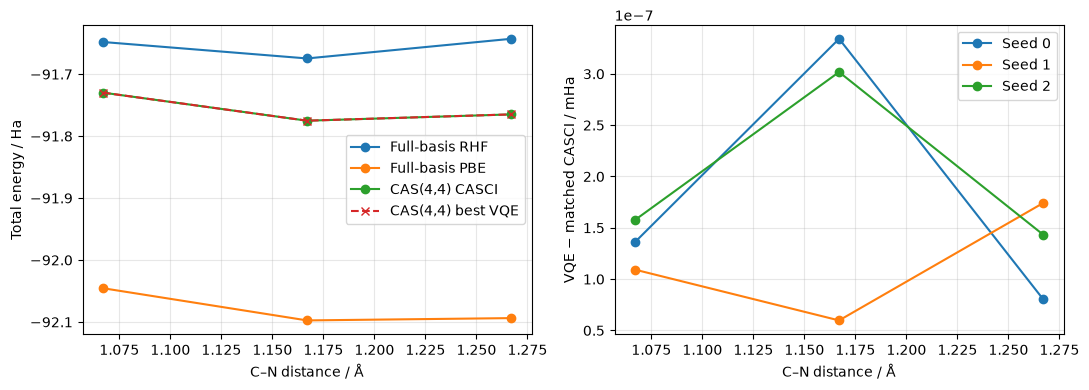

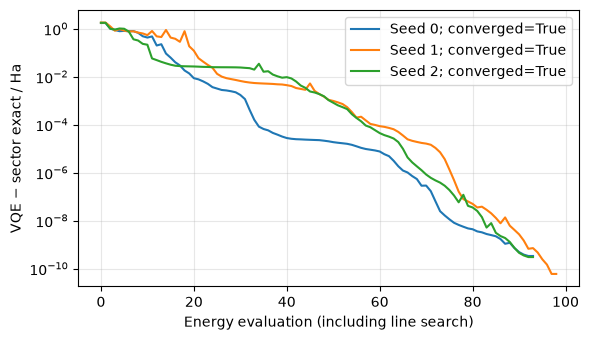

In [6]:
r = np.array([row["reference"]["r_cn_angstrom"] for row in rows])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for key, label in [("rhf_hartree", "Full-basis RHF"), ("rks_pbe_hartree", "Full-basis PBE"),
                   ("casci_hartree", "CAS(4,4) CASCI")]:
    axes[0].plot(r, [row["reference"][key] for row in rows], "o-", label=label)
axes[0].plot(r, [min(run["best_energy_hartree"] for run in row["runs"]) for row in rows],
             "x--", label="CAS(4,4) best VQE")
for seed in seeds:
    axes[1].plot(r, [1000*next(run["gap_hartree"] for run in row["runs"] if run["seed"] == seed)
                        for row in rows], "o-", label=f"Seed {seed}")
axes[0].set(xlabel="C–N distance / Å", ylabel="Total energy / Ha")
axes[1].set(xlabel="C–N distance / Å", ylabel="VQE − matched CASCI / mHa")
for ax in axes:
    ax.grid(alpha=.3)
    ax.legend()
fig.tight_layout()
plt.show()

reference_row = next(row for row in rows if abs(row["reference"]["r_cn_angstrom"]-1.167) < 1e-10)
convergence_fig, ax = plt.subplots(figsize=(6, 3.5))
for run in reference_row["runs"]:
    gaps = [max(point["energy_hartree"]-reference_row["reference"]["sector_exact_hartree"], 1e-12)
            for point in run["energy_trace"]]
    ax.semilogy(gaps, label=f"Seed {run['seed']}; converged={run['optimizer_success']}")
ax.set(xlabel="Energy evaluation (including line search)", ylabel="VQE − sector exact / Ha")
ax.grid(alpha=.3)
ax.legend()
convergence_fig.tight_layout()
plt.show()


## 5. Active-space truncation control

At the reference geometry only, compare CASCI with full STO-3G FCI using a matrix-free direct solver. This separates VQE–CASCI solver error from CASCI–full-FCI active-space truncation at fixed geometry/basis. The A₁ spatial-symmetry sector is selected from the RHF reference and singlet character is verified; other irreducible representations are not searched. The full 22-qubit dense matrix is never constructed. At this geometry, report PBE grid levels 3, 5, and 7; use level 5 and verify its agreement with level 7 within 10⁻⁶ Ha. Signed PBE–full-FCI differences remain method comparisons; approximate DFT need not satisfy the wavefunction variational bound.


In [7]:
full_fci = full_fci_reference(problem)
pbe_grid = pbe_grid_control()
best_reference_vqe = min(run["best_energy_hartree"] for run in reference_row["runs"])
solver_difference = best_reference_vqe - reference_row["reference"]["casci_hartree"]
truncation_difference = full_fci["casci_minus_full_fci_hartree"]
print("Full STO-3G FCI / Ha:", full_fci["full_fci_hartree"])
print("Full-FCI sector:", full_fci["sector"])
print("VQE − CASCI / Ha:", solver_difference)
print("CASCI − full FCI / Ha:", truncation_difference)
print("VQE − full FCI / Ha:", best_reference_vqe - full_fci["full_fci_hartree"])
print("Full-basis PBE − full FCI / Ha:", full_fci["rks_pbe_hartree"] - full_fci["full_fci_hartree"])
print("PBE grid control:", json.dumps(pbe_grid, indent=2))


Full STO-3G FCI / Ha: -91.84392763770316
Full-FCI sector: A1, Nalpha=Nbeta=7; singlet verified
VQE − CASCI / Ha: 5.969980065856362e-11
CASCI − full FCI / Ha: 0.06884275932091555
VQE − full FCI / Ha: 0.06884275938061535
Full-basis PBE − full FCI / Ha: -0.25356356479909437
PBE grid control: {
  "r_cn_angstrom": 1.167,
  "r_hc_angstrom": 1.065,
  "grid3_hartree": -92.09749232824228,
  "grid5_hartree": -92.09749120250225,
  "grid7_hartree": -92.09749122183572,
  "grid3_to5_hartree": 1.1257400274189422e-06,
  "accepted_levels": [
    5,
    7
  ],
  "delta_hartree": -1.93334699361003e-08
}


## 6. Evidence, acceptance, and limitations

Export every seed outcome and its active-integral tensors before strict checks. Saved parameters are replayed in their recorded orbital basis; fresh scalar references are checked separately, allowing for orbital phase/order choices. Default acceptance requires converged optimizers, VQE gaps below $10^{-6}$ Ha, variance below $10^{-7}$ Ha², electron number four within $10^{-10}$, $|\langle S^2\rangle|<10^{-8}$, and sector leakage below $10^{-12}$. Mapped-sector and CASCI energies must agree within $10^{-8}$ Ha; the HF determinant must recover RHF. Passing those checks validates this solver/model combination, not experimental accuracy. Frozen σ orbitals, minimal basis, restricted PBE, fixed H–C distance, and a short scan limit the chemical interpretation.

**Finding at this fixed model:** the validated default scan converges for all nine runs, with a maximum solver gap of approximately 3.34 × 10⁻¹⁰ Ha. At the reference geometry, CASCI remains 68.84 mHa above full STO-3G FCI. Active-space truncation therefore dominates the observed solver residual; this does not quantify basis-set or experimental error.


In [8]:
evidence = {"profile": profile, "provenance": metadata, "scan": rows,
            "full_fci_control": full_fci, "pbe_grid_control": pbe_grid}
output_dir = Path(os.environ.get("HCN_OUTPUT_DIR", "artifacts/hcn"))
output_dir.mkdir(parents=True, exist_ok=True)
(output_dir/"results.json").write_text(json.dumps(evidence, indent=2)+"\n")
fig.savefig(output_dir/"potential_energy_curve.png", dpi=160)
convergence_fig.savefig(output_dir/"convergence.png", dpi=160)
for row in rows:
    for run in row["runs"]:
        validate_run(run, require_accuracy=profile != "smoke")
print("PASS:", "smoke execution and symmetry checks only" if profile == "smoke"
      else "default convergence, solver-accuracy and symmetry checks")
print("Evidence saved to", output_dir)


PASS: default convergence, solver-accuracy and symmetry checks
Evidence saved to artifacts/hcn


## References

- [PySCF CASCI and active spaces](https://pyscf.org/user/mcscf.html), [FCI](https://pyscf.org/user/ci.html), and [DFT](https://pyscf.org/user/dft.html).
- [PennyLane GateFabric](https://docs.pennylane.ai/en/stable/code/api/pennylane.GateFabric.html).

Execution uses PennyLane 0.36.0. Tested versions, rejected-backend evidence, and remaining checks are recorded in [VALIDATION.md#hcn](VALIDATION.md#hcn).
